In [34]:
import os
import pandas as pd
import numpy as np

### Authenticate and Open Google Sheet
We will use the Google Colab authentication library and `gspread` to access your worksheet.

In [35]:
from google.colab import auth
auth.authenticate_user()

import gspread
from google.auth import default
creds, _ = default()

gc = gspread.authorize(creds)

### Load all tabs and combine
Replace `'YOUR_SHEET_NAME_OR_URL'` with the actual name or URL of your Google Sheet. This script will iterate through every worksheet tab and merge them.

In [36]:
import gspread
import pandas as pd

sheet_identifier = 'Copy of Digital Preservation of Instruments - AnonCopy'

try:
    if sheet_identifier.startswith('http'):
        spreadsheet = gc.open_by_url(sheet_identifier)
    else:
        spreadsheet = gc.open(sheet_identifier)

    worksheets = spreadsheet.worksheets()
    all_frames = []

    for sheet in worksheets:
        # Using get_all_values() instead of get_all_records() to avoid duplicate header errors
        rows = sheet.get_all_values()
        if rows:
            # The first row is the header
            temp_df = pd.DataFrame(rows[1:], columns=rows[0])
            temp_df['source_sheet'] = sheet.title
            all_frames.append(temp_df)

    if all_frames:
        combined_df = pd.concat(all_frames, ignore_index=True)
        print(f"Successfully combined {len(all_frames)} sheets.")
        display(combined_df.head())
    else:
        print("No data found in any of the sheets.")

except gspread.exceptions.SpreadsheetNotFound:
    print(f"Error: The spreadsheet '{sheet_identifier}' was not found.")
except Exception as e:
    print(f"An error occurred: {e}")

Successfully combined 5 sheets.


,Timestamp,I consent to participate in this study.,Name,Expertise,Instrument,Email ID,Prolific ID (Optional),Age range,What best describes your background?,"Do you currently perform music using this instrument, a related instrument, or within this musical genre?",...,"Please briefly explain what most influenced your judgement.\n(e.g., tone, phrasing, strumming, plucking, bowing, timing, expression, articulation, ornamentation, stylistic accuracy, or overall feel).",Which audio do you think is AI-generated?,"Based on your selection above, how natural does the AI generated performance sound?","Based on your selection above, how stylistically convincing does the AI generated performance sound?","Please briefly explain what most influenced your judgement.\n(e.g., tone, phrasing, strumming, plucking, bowing, timing, expression, articulation, ornamentation, stylistic accuracy, or overall feel).",Which audio do you think is AI-generated?,"Based on your selection above, how natural does the AI generated performance sound?","Based on your selection above, how stylistically convincing does the AI generated performance sound?","Please briefly explain what most influenced your judgement.\n(e.g., tone, phrasing, strumming, plucking, bowing, timing, expression, articulation, ornamentation, stylistic accuracy, or overall feel).",source_sheet
0,23/04/2026 15:58:36,Yes,AB,Novice,Sitar,AB@gmail.com,,25 - 34,General listener,No,...,overall feel,Audio 1,4,4,almost natural,Audio 2,3,4,there were a few noisy instances in the audio.,Form responses 5
1,23/04/2026 16:09:17,Yes,ABC,Novice,Sitar,ABC@gmail.com,,Under 18,General listener,No,...,its tone,Audio 1,4,4,overall feel it like ai music,Audio 2,4,3,expression,Form responses 5
2,24/04/2026 16:48:50,Yes,ABCD,Expert,Sitar,ABCD@gmail.com,,45+,Performer of a related instrument,Regularly,...,"Although it sounds like Indian slide guitar, t...",Audio 2,3,3,"It's quiet close but the phrasing, plucking,or...",Audio 1,2,2,"The plucking, expression, articulation, orname...",Form responses 5
3,26/04/2026 16:34:23,Yes,ABCDE,Novice,Sitar,ABCDE@gmail.com,,18 - 24,General listener,No,...,"Both of them are very convincing; however, the...",Audio 1,5,5,I feel the first one is slightly more agitated...,Audio 2,5,5,"Again, feel, vibe, and music consistency, tone...",Form responses 5
4,27/04/2026 13:48:51,Yes,ABCDEF,Expert,Sitar,ABCDEF@gmail.com,,45+,Music Researcher/scholar,Occasionally,...,This was a little tricky. Both sounded a littl...,Audio 1,3,3,Sounded less like a sitar because of the incre...,Audio 2,2,2,A little difficult to identify because of the ...,Form responses 5


In [37]:
combined_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26 entries, 0 to 25
Data columns (total 91 columns):
 #   Column                                                                                                                                                                                                  Non-Null Count  Dtype 
---  ------                                                                                                                                                                                                  --------------  ----- 
 0   Timestamp                                                                                                                                                                                               26 non-null     object
 1   I consent to participate in this study.                                                                                                                                                                 26 non-n

In [38]:
## Give different numbering to all with same column name


In [39]:
# Function to rename duplicate columns
def rename_duplicates(df):
    cols = pd.Series(df.columns)
    for dup in cols[cols.duplicated()].unique():
        cols[cols == dup] = [f"{dup}_{i}" if i != 0 else dup for i in range(len(cols[cols == dup]))]
    df.columns = cols
    return df

# Apply the renaming to combined_df
combined_df = rename_duplicates(combined_df)

# Verify the change
print(f"New total columns: {len(combined_df.columns)}")
ai_generated_cols_fixed = [col for col in combined_df.columns if 'Which audio do you think is AI-generated?' in col]
ai_generated_cols_fixed = ai_generated_cols_fixed + ["Instrument", "Name"]
print(f"Number of unique AI-generation questions found: {len(ai_generated_cols_fixed)}")
print("\nFirst few renamed columns:")
print(ai_generated_cols_fixed[:5])

display(combined_df[ai_generated_cols_fixed].head())

New total columns: 91
Number of unique AI-generation questions found: 21

First few renamed columns:
['Which audio do you think is AI-generated?', 'Which audio do you think is AI-generated?_1', 'Which audio do you think is AI-generated?_2', 'Which audio do you think is AI-generated?_3', 'Which audio do you think is AI-generated?_4']


,Which audio do you think is AI-generated?,Which audio do you think is AI-generated?_1,Which audio do you think is AI-generated?_2,Which audio do you think is AI-generated?_3,Which audio do you think is AI-generated?_4,Which audio do you think is AI-generated?_5,Which audio do you think is AI-generated?_6,Which audio do you think is AI-generated?_7,Which audio do you think is AI-generated?_8,Which audio do you think is AI-generated?_9,...,Which audio do you think is AI-generated?_11,Which audio do you think is AI-generated?_12,Which audio do you think is AI-generated?_13,Which audio do you think is AI-generated?_14,Which audio do you think is AI-generated?_15,Which audio do you think is AI-generated?_16,Which audio do you think is AI-generated?_17,Which audio do you think is AI-generated?_18,Instrument,Name
0,Audio 3,Audio 3,Audio 3,Audio 2,Audio 3,Audio 3,Audio 3,Audio 1,Audio 1,Audio 3,...,Audio 3,Audio 1,Audio 2,Audio 2,Audio 3,Audio 2,Audio 1,Audio 2,Sitar,AB
1,Audio 1,Audio 3,Audio 1,Audio 3,Audio 2,Audio 2,Audio 3,Audio 3,Audio 2,Audio 3,...,Audio 2,Audio 3,Audio 2,Audio 2,Audio 3,Audio 2,Audio 1,Audio 2,Sitar,ABC
2,Audio 3,Audio 3,Audio 3,Audio 2,Audio 3,Audio 2,Audio 2,Audio 3,Audio 1,Audio 3,...,Audio 3,Audio 3,Audio 2,Audio 2,Audio 3,Audio 2,Audio 2,Audio 1,Sitar,ABCD
3,Audio 3,Audio 3,Audio 3,Audio 2,Audio 3,Audio 2,Audio 1,Audio 1,Audio 1,Audio 3,...,Audio 3,Audio 3,Audio 2,Audio 2,Audio 3,Audio 1,Audio 1,Audio 2,Sitar,ABCDE
4,Audio 3,Audio 3,Audio 3,Audio 3,Audio 3,Audio 2,Audio 2,Audio 1,Audio 1,Audio 3,...,Audio 3,Audio 3,Audio 2,Audio 2,Audio 3,Audio 1,Audio 1,Audio 2,Sitar,ABCDEF


In [40]:
## Anonymized Names

combined_df["Name"].value_counts()

,count
Name,
AB,1
ABC,1
ABCD,1
ABCDE,1
ABCDEF,1
GH,1
GHI,1
GHIJ,1
GHIJK,1


In [41]:
combined_df.head()

,Timestamp,I consent to participate in this study.,Name,Expertise,Instrument,Email ID,Prolific ID (Optional),Age range,What best describes your background?,"Do you currently perform music using this instrument, a related instrument, or within this musical genre?",...,"Please briefly explain what most influenced your judgement.\n(e.g., tone, phrasing, strumming, plucking, bowing, timing, expression, articulation, ornamentation, stylistic accuracy, or overall feel)._16",Which audio do you think is AI-generated?_17,"Based on your selection above, how natural does the AI generated performance sound?_17","Based on your selection above, how stylistically convincing does the AI generated performance sound?_17","Please briefly explain what most influenced your judgement.\n(e.g., tone, phrasing, strumming, plucking, bowing, timing, expression, articulation, ornamentation, stylistic accuracy, or overall feel)._17",Which audio do you think is AI-generated?_18,"Based on your selection above, how natural does the AI generated performance sound?_18","Based on your selection above, how stylistically convincing does the AI generated performance sound?_18","Please briefly explain what most influenced your judgement.\n(e.g., tone, phrasing, strumming, plucking, bowing, timing, expression, articulation, ornamentation, stylistic accuracy, or overall feel)._18",source_sheet
0,23/04/2026 15:58:36,Yes,AB,Novice,Sitar,AB@gmail.com,,25 - 34,General listener,No,...,overall feel,Audio 1,4,4,almost natural,Audio 2,3,4,there were a few noisy instances in the audio.,Form responses 5
1,23/04/2026 16:09:17,Yes,ABC,Novice,Sitar,ABC@gmail.com,,Under 18,General listener,No,...,its tone,Audio 1,4,4,overall feel it like ai music,Audio 2,4,3,expression,Form responses 5
2,24/04/2026 16:48:50,Yes,ABCD,Expert,Sitar,ABCD@gmail.com,,45+,Performer of a related instrument,Regularly,...,"Although it sounds like Indian slide guitar, t...",Audio 2,3,3,"It's quiet close but the phrasing, plucking,or...",Audio 1,2,2,"The plucking, expression, articulation, orname...",Form responses 5
3,26/04/2026 16:34:23,Yes,ABCDE,Novice,Sitar,ABCDE@gmail.com,,18 - 24,General listener,No,...,"Both of them are very convincing; however, the...",Audio 1,5,5,I feel the first one is slightly more agitated...,Audio 2,5,5,"Again, feel, vibe, and music consistency, tone...",Form responses 5
4,27/04/2026 13:48:51,Yes,ABCDEF,Expert,Sitar,ABCDEF@gmail.com,,45+,Music Researcher/scholar,Occasionally,...,This was a little tricky. Both sounded a littl...,Audio 1,3,3,Sounded less like a sitar because of the incre...,Audio 2,2,2,A little difficult to identify because of the ...,Form responses 5


In [42]:
import json

file_path = '/content/drive/MyDrive/human_evals_selection_og/file_metadata.json'

try:
    with open(file_path, 'r') as f:
        data = json.load(f)
    print("JSON loaded successfully.")
    # Display first few keys or a portion of the data
    if isinstance(data, dict):
        print(f"Keys found: {list(data.keys())[:10]}")
    # display(data)
except FileNotFoundError:
    print(f"Error: The file at {file_path} was not found. Please check the path.")
except Exception as e:
    print(f"An error occurred: {e}")

JSON loaded successfully.
Keys found: ['Guitar_0004_utt_0001-idx3.wav', 'Guitar_0012_utt_0011-idx2.wav', 'Guitar_0030_utt_0003-idx1.wav', 'Guitar_0027_utt_0004-idx0.wav', 'Guitar_0025_utt_0011-idx4.wav', 'Guitar_0001_utt_0773-idx3-v2.wav', 'Guitar_0003_utt_0038-idx0-v1.wav', 'Guitar_0003_utt_0095-idx3-v1.wav', 'Guitar_0003_utt_0264-idx4-v1.wav', 'Guitar_0005_utt_0309-idx2-v1.wav']


In [43]:
is_ai = combined_df[ai_generated_cols_fixed]

In [44]:
models = ["suno", "lyria", "musicgen", "mustango"]
instruments = ["Guitar", "Sitar", "Sarangi", "Oud", "Violin"]

root = "/content/drive/MyDrive/human_evals_selection_og"

def find_model_name_og(file_name) :
  for model in models :
    for instrument in instruments :
      if os.path.exists(os.path.join(root, instrument, "real", model, file_name)) :
        return model


  for model in models :
    for instrument in instruments :
      if os.path.exists(os.path.join(root, instrument, model, file_name)) :
        return model

  print(file_name)

  return None


for key in data.keys() :
  data[key]["model_name"] = find_model_name_og(data[key]["filename"])

In [45]:
data

{'Guitar_0004_utt_0001-idx3.wav': {'filename': 'Guitar_0004_utt_0001-idx3.wav',
  'sampling_rate': '16k',
  'instrument': 'Guitar',
  'model': 'suno',
  'idx': 3,
  'new_name': 'Audio_idx3_v3.wav',
  'model_name': 'suno'},
 'Guitar_0012_utt_0011-idx2.wav': {'filename': 'Guitar_0012_utt_0011-idx2.wav',
  'sampling_rate': '16k',
  'instrument': 'Guitar',
  'model': 'suno',
  'idx': 2,
  'new_name': 'Audio_idx2_v1.wav',
  'model_name': 'suno'},
 'Guitar_0030_utt_0003-idx1.wav': {'filename': 'Guitar_0030_utt_0003-idx1.wav',
  'sampling_rate': 'original',
  'instrument': 'Guitar',
  'model': 'suno',
  'idx': 1,
  'new_name': 'Audio_idx1_v1.wav',
  'model_name': 'suno'},
 'Guitar_0027_utt_0004-idx0.wav': {'filename': 'Guitar_0027_utt_0004-idx0.wav',
  'sampling_rate': 'original',
  'instrument': 'Guitar',
  'model': 'suno',
  'idx': 0,
  'new_name': 'Audio_idx0_v3.wav',
  'model_name': 'suno'},
 'Guitar_0025_utt_0011-idx4.wav': {'filename': 'Guitar_0025_utt_0011-idx4.wav',
  'sampling_rate':

In [46]:
for data_ in data.values() :
  if data_["model_name"] == "lyria" :
    data_index = 0
  elif data_["model_name"] == "suno" :
    data_index = 1
  elif data_["model_name"] == "musicgen" :
    data_index = 2
  else :
    data_index = 3

  index = data_["idx"] + data_index*4
  new_name = data_["new_name"].split(".wav")[0]
  new_order = int(new_name.split("_v")[-1])

  # Corrected syntax for conditional assignment
  is_omit = 1 if data_["idx"] == 4 else 0

  position = (index, new_order, is_omit)
  data_["position"] = position

In [47]:
# data

In [48]:
def check_correctness(choice, position_0, instrument) :
  for data_ in data.values() :
    if (data_["instrument"].lower() == instrument.lower()) and (position_0 == data_["position"][0]) :
      if data_["position"][1] == choice and data_["model"] != "real" and data_["position"][2] != 1:
        return True

  return False

def check_sampling_rate(choice, position_0, instrument) :
  for data_ in data.values() :
    if (data_["instrument"].lower() == instrument.lower()) and (position_0 == data_["position"][0]) and data_["position"][2] != 1:
      # print("Found it")
      return data_["sampling_rate"]

  return None

for data_ in data.values() :
  if "position" not in data_ :
    print(data_["filename"])

## Find mappings for 16KHz sampling rates and positions and then check the number correct


for data_ in data.values() :
  if "position" not in data_ :
    print(data_["filename"])

for i, row in is_ai.iterrows() :
  for j, val in enumerate(row) :
    ## Create position id
    a_val = row.iloc[j]

    # Ignore if it's already a boolean or if it's the Instrument column or if it's not a string we can split
    if isinstance(a_val, bool) or not isinstance(a_val, str) or is_ai.columns[j].find("Which audio do you think is AI-generated?") == -1:
      continue

    try:
        a_val_int = int(a_val.split(" ")[1])
        correct_bool = check_correctness(a_val_int, j, is_ai.iloc[i]["Instrument"])

        ## Add this after each column as a new column
        is_ai.loc[i, f"Correct_{j}"] = correct_bool
        is_ai.loc[i, f"Sampling_rate_{j}"] = check_sampling_rate(a_val_int, j, is_ai.iloc[i]["Instrument"])
    except (ValueError, IndexError):
        continue

display(is_ai.head())

/tmp/ipykernel_1632/3830070088.py:42: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  is_ai.loc[i, f"Correct_{j}"] = correct_bool
/tmp/ipykernel_1632/3830070088.py:43: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  is_ai.loc[i, f"Sampling_rate_{j}"] = check_sampling_rate(a_val_int, j, is_ai.iloc[i]["Instrument"])
/tmp/ipykernel_1632/3830070088.py:42: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the cavea

,Which audio do you think is AI-generated?,Which audio do you think is AI-generated?_1,Which audio do you think is AI-generated?_2,Which audio do you think is AI-generated?_3,Which audio do you think is AI-generated?_4,Which audio do you think is AI-generated?_5,Which audio do you think is AI-generated?_6,Which audio do you think is AI-generated?_7,Which audio do you think is AI-generated?_8,Which audio do you think is AI-generated?_9,...,Correct_14,Sampling_rate_14,Correct_15,Sampling_rate_15,Correct_16,Sampling_rate_16,Correct_17,Sampling_rate_17,Correct_18,Sampling_rate_18
0,Audio 3,Audio 3,Audio 3,Audio 2,Audio 3,Audio 3,Audio 3,Audio 1,Audio 1,Audio 3,...,True,original,True,16k,False,None,False,None,False,None
1,Audio 1,Audio 3,Audio 1,Audio 3,Audio 2,Audio 2,Audio 3,Audio 3,Audio 2,Audio 3,...,True,original,True,16k,False,None,False,None,False,None
2,Audio 3,Audio 3,Audio 3,Audio 2,Audio 3,Audio 2,Audio 2,Audio 3,Audio 1,Audio 3,...,True,original,True,16k,False,None,False,None,False,None
3,Audio 3,Audio 3,Audio 3,Audio 2,Audio 3,Audio 2,Audio 1,Audio 1,Audio 1,Audio 3,...,True,original,True,16k,False,None,False,None,False,None
4,Audio 3,Audio 3,Audio 3,Audio 3,Audio 3,Audio 2,Audio 2,Audio 1,Audio 1,Audio 3,...,True,original,True,16k,False,None,False,None,False,None


In [49]:
# Define the model mapping based on your column indices
# indices 0-3: Lyria, 4-7: Suno, 8-11: Musicgen, 12-15: Mustango
model_map = {
    'Lyria': range(0, 4),
    'Suno': range(4, 8),
    'Musicgen': range(8, 12),
    'Mustango': range(12, 16)
}

# Create granular columns in is_ai for each model and sampling rate
for model_name, col_indices in model_map.items():
    for rate in ['16k', 'original']:
        col_name = f'Correct_{rate}_{model_name}'

        def check_row_performance(row, indices=col_indices, target_rate=rate):
            score = 0
            for idx in indices:
                corr_col = f'Correct_{idx}' if idx > 0 else 'Correct_0'
                rate_col = f'Sampling_rate_{idx}'

                if corr_col in row and rate_col in row:
                    if row[rate_col] == target_rate and row[corr_col] == True:
                        score += 1
            return score

        is_ai[col_name] = is_ai.apply(check_row_performance, axis=1)

# Display the new granular columns alongside participant Names
granular_cols = [col for col in is_ai.columns if 'Correct_' in col and ('16k' in col or 'original' in col)]
display(is_ai[['Instrument', 'Name'] + granular_cols].head())

/tmp/ipykernel_1632/4080677694.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  is_ai[col_name] = is_ai.apply(check_row_performance, axis=1)
/tmp/ipykernel_1632/4080677694.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  is_ai[col_name] = is_ai.apply(check_row_performance, axis=1)
/tmp/ipykernel_1632/4080677694.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentatio

,Instrument,Name,Correct_16k_Lyria,Correct_original_Lyria,Correct_16k_Suno,Correct_original_Suno,Correct_16k_Musicgen,Correct_original_Musicgen,Correct_16k_Mustango,Correct_original_Mustango
0,Sitar,AB,2,2,1,0,2,2,2,1
1,Sitar,ABC,1,0,1,1,1,0,2,2
2,Sitar,ABCD,2,2,2,2,2,2,2,2
3,Sitar,ABCDE,2,2,2,0,2,2,2,2
4,Sitar,ABCDEF,2,1,2,1,2,2,2,2


In [50]:
json.dump(data, open(os.path.join(root, "file_metadata_og.json"), "w"))

In [51]:
## Sum up all columns with Correct as the substring in column_name

# columns_correct = [col for col in is_ai.columns if "Correct" in col][:16]
print([col for col in is_ai.columns if "Correct" in col and "original" not in col and "16k" not in col])
columns_correct = [col for col in is_ai.columns if "Correct" in col and "original" not in col and "16k" not in col]

## Merge combined_df using Name
combined_df = pd.merge(combined_df, is_ai[["Name"] + columns_correct], on="Name", how="left")

['Correct_0', 'Correct_1', 'Correct_2', 'Correct_3', 'Correct_4', 'Correct_5', 'Correct_6', 'Correct_7', 'Correct_8', 'Correct_9', 'Correct_10', 'Correct_11', 'Correct_12', 'Correct_13', 'Correct_14', 'Correct_15', 'Correct_16', 'Correct_17', 'Correct_18']


In [52]:
combined_df.head()

,Timestamp,I consent to participate in this study.,Name,Expertise,Instrument,Email ID,Prolific ID (Optional),Age range,What best describes your background?,"Do you currently perform music using this instrument, a related instrument, or within this musical genre?",...,Correct_9,Correct_10,Correct_11,Correct_12,Correct_13,Correct_14,Correct_15,Correct_16,Correct_17,Correct_18
0,23/04/2026 15:58:36,Yes,AB,Novice,Sitar,AB@gmail.com,,25 - 34,General listener,No,...,True,True,True,False,True,True,True,False,False,False
1,23/04/2026 16:09:17,Yes,ABC,Novice,Sitar,ABC@gmail.com,,Under 18,General listener,No,...,True,False,False,True,True,True,True,False,False,False
2,24/04/2026 16:48:50,Yes,ABCD,Expert,Sitar,ABCD@gmail.com,,45+,Performer of a related instrument,Regularly,...,True,True,True,True,True,True,True,False,False,False
3,26/04/2026 16:34:23,Yes,ABCDE,Novice,Sitar,ABCDE@gmail.com,,18 - 24,General listener,No,...,True,True,True,True,True,True,True,False,False,False
4,27/04/2026 13:48:51,Yes,ABCDEF,Expert,Sitar,ABCDEF@gmail.com,,45+,Music Researcher/scholar,Occasionally,...,True,True,True,True,True,True,True,False,False,False


In [53]:
## Get all correct columns for each row and then sum them

combined_df["Correct_sum"] = combined_df[columns_correct].sum(axis=1)


In [54]:
combined_df[["Name", "Correct_sum"]]

,Name,Correct_sum
0,AB,12
1,ABC,8
2,ABCD,16
3,ABCDE,14
4,ABCDEF,14
5,GH,13
6,GHI,12
7,GHIJ,16
8,GHIJK,16
9,GHIJKL,7


In [55]:
combined_df[combined_df["Name"] == "Arjun Gangwar"][columns_correct]

,Correct_0,Correct_1,Correct_2,Correct_3,Correct_4,Correct_5,Correct_6,Correct_7,Correct_8,Correct_9,Correct_10,Correct_11,Correct_12,Correct_13,Correct_14,Correct_15,Correct_16,Correct_17,Correct_18


In [56]:
lyria_columns = columns_correct[:4]
suno_columns = columns_correct[4:8]
musicgen_columns = columns_correct[8:12]
mustango_columns = columns_correct[12:]

combined_df["Correct_Lyria"] = combined_df[lyria_columns].sum(axis=1)
combined_df["Correct_Suno"] = combined_df[suno_columns].sum(axis=1)
combined_df["Correct_Musicgen"] = combined_df[musicgen_columns].sum(axis=1)
combined_df["Correct_Mustango"] = combined_df[mustango_columns].sum(axis=1)

In [57]:
combined_df[["Name", "Correct_Lyria", "Correct_Suno", "Correct_Musicgen", "Correct_Mustango", "Instrument", "Expertise"]]

,Name,Correct_Lyria,Correct_Suno,Correct_Musicgen,Correct_Mustango,Instrument,Expertise
0,AB,4,1,4,3,Sitar,Novice
1,ABC,1,2,1,4,Sitar,Novice
2,ABCD,4,4,4,4,Sitar,Expert
3,ABCDE,4,2,4,4,Sitar,Novice
4,ABCDEF,3,3,4,4,Sitar,Expert
5,GH,1,4,4,4,Sarangi,Novice
6,GHI,0,4,4,4,Sarangi,Novice
7,GHIJ,4,4,4,4,Sarangi,Expert
8,GHIJK,4,4,4,4,Sarangi,Expert
9,GHIJKL,3,2,1,1,Sarangi,Novice


In [58]:
combined_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26 entries, 0 to 25
Columns: 115 entries, Timestamp to Correct_Mustango
dtypes: object(115)
memory usage: 23.5+ KB


In [59]:
combined_df.to_csv("Processed_Data.csv")

In [60]:
Select_zero = 16/81 ## For never selecting the correct
Select_once = 32/81 ## For selecting correct atleast once
Select_twice = 1 - 57/81 ## For
Select_thrice = 8/81
Select_four = 1/81




In [61]:
combined_df.groupby(by="Instrument")["Correct_sum"]

In [62]:
# Calculate and display the average correctness sum for each instrument
instrument_avg = combined_df.groupby('Instrument')['Correct_sum'].mean().reset_index()
instrument_avg.columns = ['Instrument', 'Average_Correct_Count']

# Display the results sorted by average performance
display(instrument_avg.sort_values(by='Average_Correct_Count', ascending=False))

,Instrument,Average_Correct_Count
2,Sarangi,12.8
3,Sitar,12.8
4,Violin,9.0
0,Guitar,8.166667
1,Oud,7.8


In [63]:
# Check agreement between people from same instrument groupsinstrument_name_list = ["Oud", "Sarangi", "Sitar", "Violin", "Guitar"]

Non-expert Evals

In [64]:
non_expert_df = combined_df[combined_df["Expertise"] == "Novice"]

In [65]:
import numpy as np
from statsmodels.stats.inter_rater import fleiss_kappa

# # 5 items, 3 annotators, 3 categories
# ratings = np.array([
#     [3, 0, 0],
#     [2, 1, 0],
#     [0, 3, 0],
#     [1, 1, 1],
#     [0, 2, 1],
# ])

# kappa = fleiss_kappa(ratings)
# print(kappa)

kappa_scores_ne = []
# accuracy_ne = []

for inst in instruments :
  inst_df = non_expert_df[non_expert_df["Instrument"] == inst]

  q_columns = [col for col in non_expert_df.columns if 'Which audio do you think is AI-generated?' in col]
  q_inst_df = inst_df[q_columns]
  model_comparison_columns = q_columns[16:]
  q_columns = q_columns[:16]

  ## Check column wise agreements
  total_agg = 0
  selections = []

  for col in q_columns :
    if q_inst_df[col].nunique() == 1 :
      total_agg += 1
    # print(np.array(inst_df[col].value_counts().index))

    ## Convert index to int by taking only last character and int()
    choice = np.array(q_inst_df[col].value_counts().index)
    count = np.array(q_inst_df[col].value_counts())
    choice = [(int(x[-1]) - 1) for x in choice]
    choice_count = np.zeros(3)
    choice_count[choice] = count
    # print(choice_count)

    selections.append(choice_count)

  fleiss_kappa_s = fleiss_kappa(np.array(selections))
  print(f"Fleiss Kappa for instrument : {inst} is {fleiss_kappa_s}")

  kappa_scores_ne.append(fleiss_kappa_s)
  # accuracy_ne.append(total_agg/16)

  total_agg = 100*total_agg/16

  print(f"Annotator agreement for AI vs Human with instrument : {inst} is {total_agg}")

  # Model-wise IAA for the first 16 questions
  model_q_ranges = {
      "Lyria": q_columns[0:4],
      "Suno": q_columns[4:8],
      "Musicgen": q_columns[8:12],
      "Mustango": q_columns[12:16]
  }

  for model_name, cols in model_q_ranges.items():
      model_selections = []
      for col in cols:
          if q_inst_df[col].empty:
              continue
          choice = np.array(q_inst_df[col].value_counts().index)
          count = np.array(q_inst_df[col].value_counts())
          choice = [(int(x[-1]) - 1) for x in choice]
          choice_count = np.zeros(3)
          choice_count[choice] = count
          model_selections.append(choice_count)

      if model_selections:
          fleiss_kappa_model = fleiss_kappa(np.array(model_selections))
          print(f"  Fleiss Kappa for {model_name} (instrument {inst}): {fleiss_kappa_model}")
      else:
          print(f"  No data for {model_name} (instrument {inst}) to calculate Fleiss Kappa.")

  total_agg = 0
  selections = []

  for col in model_comparison_columns :
    if inst_df[col].nunique() == 1 :
      total_agg += 1

     ## Convert index to int by taking only last character and int()
    choice = np.array(q_inst_df[col].value_counts().index)
    count = np.array(q_inst_df[col].value_counts())
    choice = [(int(x[-1]) - 1) for x in choice]
    choice_count = np.zeros(3)
    choice_count[choice] = count
    # print(choice_count)

    selections.append(choice_count)

  fleiss_kappa_s = fleiss_kappa(np.array(selections))
  print(f"Fleiss Kappa for instrument : {inst} is {fleiss_kappa_s}")

  total_agg = 100*total_agg/3

  print(f"Model agreement for AI vs Human with instrument : {inst} is {total_agg}")
  print("-------------------------------------------------------------------------")


Fleiss Kappa for instrument : Guitar is 0.07948523845571537
Annotator agreement for AI vs Human with instrument : Guitar is 6.25
  Fleiss Kappa for Lyria (instrument Guitar): 0.07246376811594203
  Fleiss Kappa for Suno (instrument Guitar): -0.00483091787439617
  Fleiss Kappa for Musicgen (instrument Guitar): -0.0958904109589041
  Fleiss Kappa for Mustango (instrument Guitar): -0.06666666666666672
Fleiss Kappa for instrument : Guitar is -0.2500000000000001
Model agreement for AI vs Human with instrument : Guitar is 0.0
-------------------------------------------------------------------------
Fleiss Kappa for instrument : Sitar is 0.22807017543859642
Annotator agreement for AI vs Human with instrument : Sitar is 31.25
  Fleiss Kappa for Lyria (instrument Sitar): -1.1102230246251565e-16
  Fleiss Kappa for Suno (instrument Sitar): -0.0666666666666667
  Fleiss Kappa for Musicgen (instrument Sitar): 0.12195121951219488
  Fleiss Kappa for Mustango (instrument Sitar): 0.7073170731707316
Fleiss

In [66]:
## Model preference
model_preference_order = [("lyria", "suno"), ("suno", "musicgen"), ("musicgen", "mustango")]
# For remaining 3 questions these are the comparisons and we have to see the preference order (can do through elo?)
for inst in instruments :
  inst_df = non_expert_df[non_expert_df["Instrument"] == inst]

  q_columns = [col for col in non_expert_df.columns if 'Which audio do you think is AI-generated?' in col]
  q_inst_df = inst_df[q_columns]
  model_comparison_columns = q_columns[16:]
  q_columns = q_columns[:16]

  ## Now do majority voting across rows
  selections = []
  for col in model_comparison_columns :
    choice = np.array(q_inst_df[col].value_counts().index)
    count = np.array(q_inst_df[col].value_counts())
    choice = [(int(x[-1]) - 1) for x in choice]
    choice_count = np.zeros(2)
    # print(sum(count))
    # print(count)
    choice_count[choice] = count
    choice_count = sum(count) - choice_count
    # print(choice_count)

    selections.append(choice_count)

  print(f"Instrument {inst}; {selections}")

Instrument Guitar; [array([3., 1.]), array([2., 2.]), array([3., 1.])]
Instrument Sitar; [array([2., 1.]), array([0., 3.]), array([3., 0.])]
Instrument Sarangi; [array([3., 0.]), array([0., 3.]), array([2., 1.])]
Instrument Oud; [array([2., 1.]), array([3., 0.]), array([3., 0.])]
Instrument Violin; [array([3., 0.]), array([2., 1.]), array([3., 0.])]


In [67]:
non_expert_df.head()

,Timestamp,I consent to participate in this study.,Name,Expertise,Instrument,Email ID,Prolific ID (Optional),Age range,What best describes your background?,"Do you currently perform music using this instrument, a related instrument, or within this musical genre?",...,Correct_14,Correct_15,Correct_16,Correct_17,Correct_18,Correct_sum,Correct_Lyria,Correct_Suno,Correct_Musicgen,Correct_Mustango
0,23/04/2026 15:58:36,Yes,AB,Novice,Sitar,AB@gmail.com,,25 - 34,General listener,No,...,True,True,False,False,False,12,4,1,4,3
1,23/04/2026 16:09:17,Yes,ABC,Novice,Sitar,ABC@gmail.com,,Under 18,General listener,No,...,True,True,False,False,False,8,1,2,1,4
3,26/04/2026 16:34:23,Yes,ABCDE,Novice,Sitar,ABCDE@gmail.com,,18 - 24,General listener,No,...,True,True,False,False,False,14,4,2,4,4
5,23/04/2026 15:48:53,No,GH,Novice,Sarangi,GH@gmail.com,,18 - 24,General listener,No,...,True,True,False,False,False,13,1,4,4,4
6,23/04/2026 16:07:18,Yes,GHI,Novice,Sarangi,GHI@gmail.com,,25 - 34,General listener,No,...,True,True,False,False,False,12,0,4,4,4


In [68]:
## All columns with Sampling_Rate_{} template to be compared with Correct columns for getting an idea of how many correct for which sampling rate


In [69]:
# Identify the granular columns created for models and sampling rates
granular_cols = [col for col in non_expert_df.columns if 'Correct_' in col and not ('16k' in col or 'original' in col)]

# Group by Instrument and calculate the mean for these columns
instrument_model_perf = non_expert_df.groupby('Instrument')[granular_cols].sum()

# Display the results
print("Average Correct Identification by Instrument and Model (Non-Experts):")
display(instrument_model_perf.style.background_gradient(cmap='Blues'))

Average Correct Identification by Instrument and Model (Non-Experts):


,Correct_0,Correct_1,Correct_2,Correct_3,Correct_4,Correct_5,Correct_6,Correct_7,Correct_8,Correct_9,Correct_10,Correct_11,Correct_12,Correct_13,Correct_14,Correct_15,Correct_16,Correct_17,Correct_18,Correct_sum,Correct_Lyria,Correct_Suno,Correct_Musicgen,Correct_Mustango
Instrument,,,,,,,,,,,,,,,,,,,,,,,,
Guitar,0,2,0,4,2,0,1,3,3,2,2,3,2,2,2,1,0,0,0,29,6,6,10,7
Oud,0,0,1,1,0,1,1,0,3,0,2,1,3,2,1,3,0,0,0,19,2,2,6,9
Sarangi,1,0,1,2,2,3,3,2,2,2,2,3,2,2,3,2,0,0,0,32,4,10,9,9
Sitar,2,3,2,2,2,2,0,1,2,3,2,2,2,3,3,3,0,0,0,34,9,5,9,11
Violin,0,1,0,1,1,1,1,1,0,2,2,3,3,2,1,3,0,0,0,22,2,4,7,9


In [70]:
combined_df["Expertise"] = combined_df["Expertise"].str.strip()
expert_df = combined_df[combined_df["Expertise"] == "Expert"]

In [71]:
import numpy as np
from statsmodels.stats.inter_rater import fleiss_kappa

# # 5 items, 3 annotators, 3 categories
# ratings = np.array([
#     [3, 0, 0],
#     [2, 1, 0],
#     [0, 3, 0],
#     [1, 1, 1],
#     [0, 2, 1],
# ])

# kappa = fleiss_kappa(ratings)
# print(kappa)

kappa_scores_e = []
# accuracy_e = []

for inst in instruments :
  inst_df = expert_df[expert_df["Instrument"] == inst]

  # print(inst_df["Name"].value_counts())

  q_columns = [col for col in expert_df.columns if 'Which audio do you think is AI-generated?' in col]
  q_inst_df = inst_df[q_columns]
  model_comparison_columns = q_columns[16:]
  q_columns = q_columns[:16]


  ## Check column wise agreements
  total_agg = 0
  selections = []

  ## Check model wise

  for col in q_columns :
    if q_inst_df[col].nunique() == 1 :
      total_agg += 1
    # print(np.array(inst_df[col].value_counts().index))

    ## Convert index to int by taking only last character and int()
    choice = np.array(q_inst_df[col].value_counts().index)
    count = np.array(q_inst_df[col].value_counts())
    choice = [(int(x[-1]) - 1) for x in choice]
    choice_count = np.zeros(3)
    choice_count[choice] = count
    # print(choice_count)

    selections.append(choice_count)

  # print(selections)
  fleiss_kappa_s = fleiss_kappa(np.array(selections))
  print(f"Fleiss Kappa for instrument : {inst} is {fleiss_kappa_s}")

  kappa_scores_e.append(fleiss_kappa_s)
  # accuracy_e.append(total_agg/16)

  total_agg = 100*total_agg/16

  print(f"Annotator agreement for AI vs Human with instrument : {inst} is {total_agg}")

  # Model-wise IAA for the first 16 questions
  model_q_ranges = {
      "Lyria": q_columns[0:4],
      "Suno": q_columns[4:8],
      "Musicgen": q_columns[8:12],
      "Mustango": q_columns[12:16]
  }

  for model_name, cols in model_q_ranges.items():
      model_selections = []
      for col in cols:
          if q_inst_df[col].empty:
              continue
          choice = np.array(q_inst_df[col].value_counts().index)
          count = np.array(q_inst_df[col].value_counts())
          choice = [(int(x[-1]) - 1) for x in choice]
          choice_count = np.zeros(3)
          choice_count[choice] = count
          model_selections.append(choice_count)

      if model_selections:
          fleiss_kappa_model = fleiss_kappa(np.array(model_selections))
          print(f"  Fleiss Kappa for {model_name} (instrument {inst}): {fleiss_kappa_model}")
      else:
          print(f"  No data for {model_name} (instrument {inst}) to calculate Fleiss Kappa.")


  total_agg = 0
  selections = []

  for col in model_comparison_columns :
    if inst_df[col].nunique() == 1 :
      total_agg += 1

     ## Convert index to int by taking only last character and int()
    choice = np.array(q_inst_df[col].value_counts().index)
    count = np.array(q_inst_df[col].value_counts())
    choice = [(int(x[-1]) - 1) for x in choice]
    choice_count = np.zeros(3)
    choice_count[choice] = count
    # print(choice_count)

    selections.append(choice_count)

  fleiss_kappa_s = fleiss_kappa(np.array(selections))
  print(f"Fleiss Kappa for instrument : {inst} is {fleiss_kappa_s}")


  total_agg = 100*total_agg/3

  print(f"Model agreement for AI vs Human with instrument : {inst} is {total_agg}")
  print("-------------------------------------------------------------------------")

Fleiss Kappa for instrument : Guitar is 0.26557377049180325
Annotator agreement for AI vs Human with instrument : Guitar is 56.25
  Fleiss Kappa for Lyria (instrument Guitar): -0.14285714285714285
  Fleiss Kappa for Suno (instrument Guitar): 0.4666666666666667
  Fleiss Kappa for Musicgen (instrument Guitar): -0.14285714285714285
  Fleiss Kappa for Mustango (instrument Guitar): 0.15789473684210525
Fleiss Kappa for instrument : Guitar is 0.33333333333333326
Model agreement for AI vs Human with instrument : Guitar is 66.66666666666667
-------------------------------------------------------------------------
Fleiss Kappa for instrument : Sitar is 0.7602996254681648
Annotator agreement for AI vs Human with instrument : Sitar is 87.5
  Fleiss Kappa for Lyria (instrument Sitar): -0.14285714285714285
  Fleiss Kappa for Suno (instrument Sitar): 0.5789473684210527
  Fleiss Kappa for Musicgen (instrument Sitar): 1.0
  Fleiss Kappa for Mustango (instrument Sitar): 1.0
Fleiss Kappa for instrument :

In [72]:
# kappa_scores_e[0] = 0.4

acc_expert = expert_df.groupby("Instrument")["Correct_sum"].mean()
acc_nonexpert = non_expert_df.groupby("Instrument")["Correct_sum"].mean()

acc_expert_suno = expert_df.groupby("Instrument")["Correct_Suno"].mean()/4
acc_expert_musicgen = expert_df.groupby("Instrument")["Correct_Musicgen"].mean()/4
acc_expert_mustango = expert_df.groupby("Instrument")["Correct_Mustango"].mean()/4
acc_expert_lyria = expert_df.groupby("Instrument")["Correct_Lyria"].mean()/4

acc_nonexpert_suno = non_expert_df.groupby("Instrument")["Correct_Suno"].mean()/4
acc_nonexpert_musicgen = non_expert_df.groupby("Instrument")["Correct_Musicgen"].mean()/4
acc_nonexpert_mustango = non_expert_df.groupby("Instrument")["Correct_Mustango"].mean()/4
acc_nonexpert_lyria = non_expert_df.groupby("Instrument")["Correct_Lyria"].mean()/4

print(acc_expert/16)
print(acc_nonexpert/16)

accuracy_e = acc_expert/16
accuracy_ne = acc_nonexpert/16

accuracy_e = accuracy_e.tolist()
accuracy_ne = accuracy_ne.tolist()

acc_nonexpert = [acc_nonexpert_lyria.tolist(), acc_nonexpert_suno.tolist(), acc_nonexpert_musicgen.tolist(), acc_nonexpert_mustango.tolist()]
acc_expert = [acc_expert_lyria.tolist(), acc_expert_suno.tolist(), acc_expert_musicgen.tolist(), acc_expert_mustango.tolist()]

acc_nonexpert = np.array(acc_nonexpert).T
acc_expert = np.array(acc_expert).T

print(acc_expert.shape)
print(acc_nonexpert.shape)

Instrument
Guitar       0.625
Oud          0.625
Sarangi        1.0
Sitar       0.9375
Violin     0.71875
Name: Correct_sum, dtype: object
Instrument
Guitar     0.453125
Oud        0.395833
Sarangi    0.666667
Sitar      0.708333
Violin     0.458333
Name: Correct_sum, dtype: object
(5, 4)
(5, 4)


In [73]:
print(acc_expert)
print(acc_nonexpert)

[[0.625 0.875 0.875 0.125]
 [0.25  0.75  0.5   1.   ]
 [1.    1.    1.    1.   ]
 [0.875 0.875 1.    1.   ]
 [0.375 0.75  1.    0.75 ]]
[[0.375      0.375      0.625      0.4375    ]
 [0.16666667 0.16666667 0.5        0.75      ]
 [0.33333333 0.83333333 0.75       0.75      ]
 [0.75       0.41666667 0.75       0.91666667]
 [0.16666667 0.33333333 0.58333333 0.75      ]]


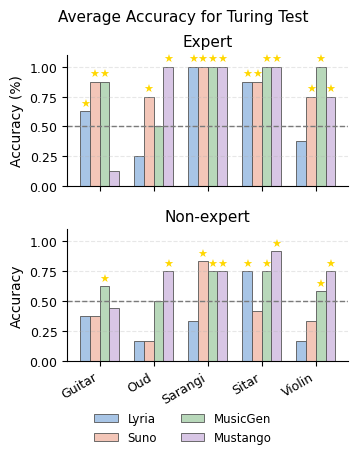

In [74]:
import matplotlib.pyplot as plt
import numpy as np

# Ensure data is defined and as numpy arrays for slicing
# Based on previous calculations:
instruments = ["Guitar", "Oud", "Sarangi", "Sitar", "Violin"]
models = ["Lyria", "Suno", "MusicGen", "Mustango"]

# Re-calculating/re-assigning to ensure they are available for this cell
acc_expert_vals = [acc_expert_lyria.tolist(), acc_expert_suno.tolist(), acc_expert_musicgen.tolist(), acc_expert_mustango.tolist()]
acc_nonexpert_vals = [acc_nonexpert_lyria.tolist(), acc_nonexpert_suno.tolist(), acc_nonexpert_musicgen.tolist(), acc_nonexpert_mustango.tolist()]

acc_expert_plot = np.array(acc_expert_vals).T
acc_nonexpert_plot = np.array(acc_nonexpert_vals).T

# Softer palette
colors = ["#A8C5E6", "#F3C6B8", "#B8D8BA", "#D8C6E5"]

x = np.arange(len(instruments))
width = 0.18

plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8.5,
})

fig, axes = plt.subplots(2, 1, figsize=(3.6, 4.9), sharex=True, sharey=True)
fig.suptitle("Average Accuracy for Turing Test", fontsize=11, y=0.90)

# Expert Plot
for i, model in enumerate(models):
    bars = axes[0].bar(
        x + (i - 1.5) * width, acc_expert_plot[:, i], width,
        label=model, color=colors[i], edgecolor="#555555", linewidth=0.6
    )
    for bar in bars:
        if bar.get_height() > 0.5:
            axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, '★',
                         ha='center', va='bottom', color='gold', fontsize=8)

axes[0].set_title("Expert")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(0, 1.1)
axes[0].grid(axis="y", linestyle="--", alpha=0.3)
axes[0].spines[["top", "right"]].set_visible(False)

# Non-expert Plot
for i, model in enumerate(models):
    bars = axes[1].bar(
        x + (i - 1.5) * width, acc_nonexpert_plot[:, i], width,
        label=model, color=colors[i], edgecolor="#555555", linewidth=0.6
    )
    for bar in bars:
        if bar.get_height() > 0.5:
            axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02, '★',
                         ha='center', va='bottom', color='gold', fontsize=8)


axes[1].axhline(0.5, color="#7A7A7A", linestyle="--", linewidth=1.0)
axes[1].set_title("Non-expert")
axes[1].set_ylabel("Accuracy")
axes[1].set_xticks(x)
axes[1].set_xticklabels(instruments, rotation=30, ha="right")
axes[1].set_ylim(0, 1.1)
axes[1].grid(axis="y", linestyle="--", alpha=0.3)
axes[1].spines[["top", "right"]].set_visible(False)

fig.legend(models, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.01))
axes[0].axhline(0.5, color="#7A7A7A", linestyle="--", linewidth=1.0)
fig.tight_layout(rect=[0, 0.06, 1, 0.94])

plt.savefig("accuracy_plt.pdf", bbox_inches="tight")

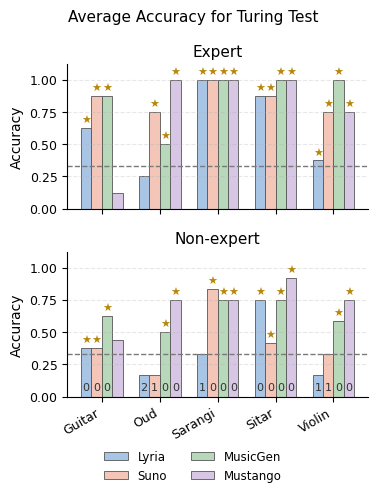

In [75]:
import matplotlib.pyplot as plt
import numpy as np

instruments = ["Guitar", "Oud", "Sarangi", "Sitar", "Violin"]
models = ["Lyria", "Suno", "MusicGen", "Mustango"]

acc_expert_vals = [acc_expert_lyria.tolist(), acc_expert_suno.tolist(), acc_expert_musicgen.tolist(), acc_expert_mustango.tolist()]
acc_nonexpert_vals = [acc_nonexpert_lyria.tolist(), acc_nonexpert_suno.tolist(), acc_nonexpert_musicgen.tolist(), acc_nonexpert_mustango.tolist()]

acc_expert_plot = np.array(acc_expert_vals).T
acc_nonexpert_plot = np.array(acc_nonexpert_vals).T

colors = ["#A8C5E6", "#F3C6B8", "#B8D8BA", "#D8C6E5"]

x = np.arange(len(instruments))
width = 0.18
threshold = 1/3

plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 8.5,
})

fig, axes = plt.subplots(2, 1, figsize=(3.8, 5.2), sharex=True, sharey=True)
fig.suptitle("Average Accuracy for Turing Test", fontsize=11, y=0.92)

# Expert plot
for i, model in enumerate(models):
    xpos = x + (i - 1.5) * width
    bars = axes[0].bar(
        xpos, acc_expert_plot[:, i], width,
        label=model, color=colors[i], edgecolor="#555555", linewidth=0.6
    )
    for bar in bars:
        if bar.get_height() > threshold:
            axes[0].text(
                bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.02,
                "★",
                ha="center", va="bottom",
                color="darkgoldenrod", fontsize=8
            )

axes[0].set_title("Expert")
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0, 1.12)
axes[0].grid(axis="y", linestyle="--", alpha=0.3)
axes[0].spines[["top", "right"]].set_visible(False)

# Non-expert plot + score annotation
for i, model in enumerate(models):
    xpos = x + (i - 1.5) * width
    bars = axes[1].bar(
        xpos, acc_nonexpert_plot[:, i], width,
        label=model, color=colors[i], edgecolor="#555555", linewidth=0.6
    )

    for j, bar in enumerate(bars):
        if model == "Mustango" and j == 0:
            continue

        e_pass = acc_expert_plot[j, i] > threshold
        ne_pass = acc_nonexpert_plot[j, i] > threshold

        if bar.get_height() > threshold:
            axes[1].text(
                bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.02,
                "★",
                ha="center", va="bottom",
                color="darkgoldenrod", fontsize=8
            )

        # perception score
        if e_pass and ne_pass:
            score = 0
        elif (not ne_pass) and e_pass:
            score = 1
        else:
            score = 2

        axes[1].text(
            bar.get_x() + bar.get_width()/2,
            0.03,
            str(score),
            ha="center", va="bottom",
            fontsize=8, color="#333333"
        )

axes[1].axhline(threshold, color="#7A7A7A", linestyle="--", linewidth=1.0)
axes[1].set_title("Non-expert")
axes[1].set_ylabel("Accuracy")
axes[1].set_xticks(x)
axes[1].set_xticklabels(instruments, rotation=30, ha="right")
axes[1].set_ylim(0, 1.12)
axes[1].grid(axis="y", linestyle="--", alpha=0.3)
axes[1].spines[["top", "right"]].set_visible(False)

fig.legend(models, loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.01))
axes[0].axhline(threshold, color="#7A7A7A", linestyle="--", linewidth=1.0)
fig.tight_layout(rect=[0, 0.06, 1, 0.94])

plt.savefig("accuracy_plt_with_scores.pdf", bbox_inches="tight")
plt.show()

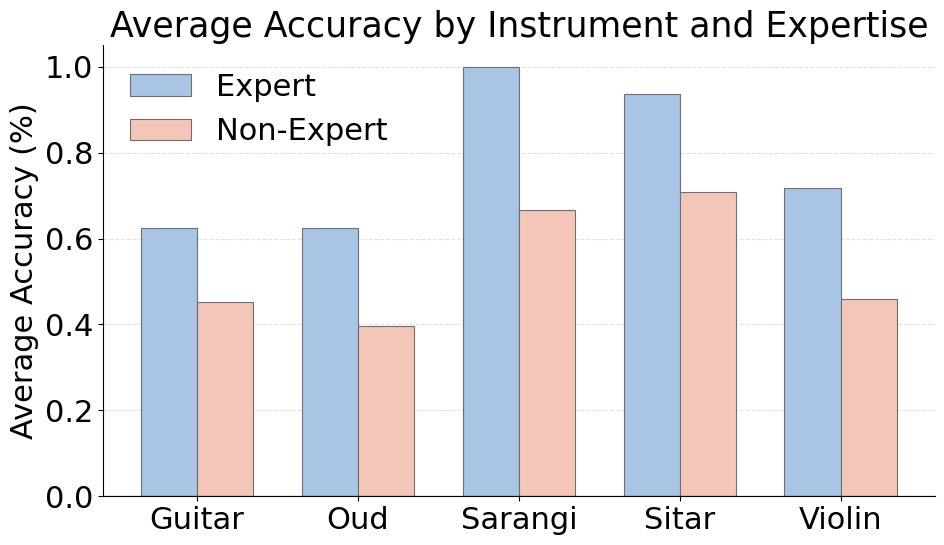

In [76]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare data for plotting
# Note: Handling potential nan values by converting them to 0 for visualization purposes
plot_kappa_e = [0 if np.isnan(x) else x for x in accuracy_e]
plot_kappa_ne = [0 if np.isnan(x) else x for x in accuracy_ne]

x = np.arange(len(instruments))
width = 0.35

# Softer pastel palette
expert_color = "#A8C5E6"      # pastel blue
nonexpert_color = "#F3C6B8"   # pastel peach
edge_color = "#6E6E6E"

# Larger font sizes
plt.rcParams.update({
    "font.size": 25,
    "axes.titlesize": 25,
    "axes.labelsize": 22,
    "xtick.labelsize": 22,
    "ytick.labelsize": 22,
    "legend.fontsize": 22
})

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(
    x - width/2, plot_kappa_e, width,
    label='Expert', color=expert_color, edgecolor=edge_color, linewidth=0.8
)
rects2 = ax.bar(
    x + width/2, plot_kappa_ne, width,
    label='Non-Expert', color=nonexpert_color, edgecolor=edge_color, linewidth=0.8
)

ax.set_ylabel('Average Accuracy (%)')
ax.set_title('Average Accuracy by Instrument and Expertise')
ax.set_xticks(x)
ax.set_xticklabels(instruments)
ax.legend(frameon=False)

ax.axhline(0, color='black', linewidth=0.8)
ax.grid(axis='y', linestyle='--', alpha=0.45, color="#BFBFBF")
ax.set_axisbelow(True)

# Clean up spines for a softer look
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

fig.tight_layout()
plt.show()

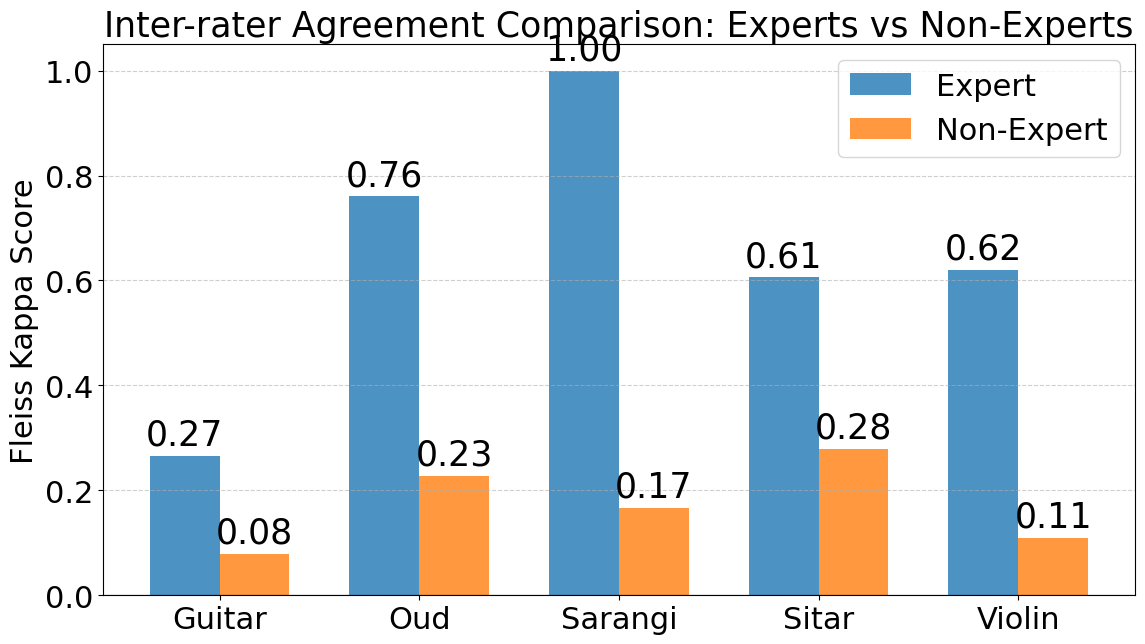

In [77]:
import matplotlib.pyplot as plt
import numpy as np

# Handle potential NaN values by converting them to 0 for visualization
# Using the kappa scores calculated in the previous analysis turns
clean_kappa_e = [0 if (np.isnan(x) or x is None) else x for x in kappa_scores_e]
clean_kappa_ne = [0 if (np.isnan(x) or x is None) else x for x in kappa_scores_ne]

x = np.arange(len(instruments))
width = 0.35

fig, ax = plt.subplots(figsize=(12, 7))

# Create bars for Expert and Non-Expert side by side
rects1 = ax.bar(x - width/2, clean_kappa_e, width, label='Expert', color='#1f77b4', alpha=0.8)
rects2 = ax.bar(x + width/2, clean_kappa_ne, width, label='Non-Expert', color='#ff7f0e', alpha=0.8)

# Labels and styling
ax.set_ylabel('Fleiss Kappa Score')
ax.set_title('Inter-rater Agreement Comparison: Experts vs Non-Experts')
ax.set_xticks(x)
ax.set_xticklabels(instruments)
ax.legend()

# Add a horizontal line at 0 and a grid for readability
ax.axhline(0, color='black', linewidth=0.8)
plt.grid(axis='y', linestyle='--', alpha=0.6)

# Add value labels on top of bars
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom')

autolabel(rects1)
autolabel(rects2)

fig.tight_layout()
plt.show()

In [78]:
## Model preference
model_preference_order = [("lyria", "suno"), ("suno", "musicgen"), ("musicgen", "mustango")]
# For remaining 3 questions these are the comparisons and we have to see the preference order (can do through elo?)
for inst in instruments :
  inst_df = expert_df[expert_df["Instrument"] == inst]

  q_columns = [col for col in expert_df.columns if 'Which audio do you think is AI-generated?' in col]
  q_inst_df = inst_df[q_columns]
  model_comparison_columns = q_columns[16:]
  q_columns = q_columns[:16]

  ## Now do majority voting across rows
  selections = []
  for col in model_comparison_columns :
    choice = np.array(q_inst_df[col].value_counts().index)
    count = np.array(q_inst_df[col].value_counts())
    choice = [(int(x[-1]) - 1) for x in choice]
    choice_count = np.zeros(2)
    # print(sum(count))
    # print(count)
    choice_count[choice] = count
    choice_count = sum(count) - choice_count
    # print(choice_count)

    selections.append(choice_count)

  print(f"Instrument {inst}; {selections}")

Instrument Guitar; [array([2., 0.]), array([1., 1.]), array([0., 2.])]
Instrument Oud; [array([1., 1.]), array([2., 0.]), array([2., 0.])]
Instrument Sarangi; [array([0., 2.]), array([2., 0.]), array([1., 1.])]
Instrument Sitar; [array([1., 1.]), array([1., 1.]), array([1., 1.])]
Instrument Violin; [array([2., 0.]), array([1., 1.]), array([2., 0.])]


In [79]:
### Need to find the number of disagreements between experts and non-experts

expert_majority_votes = {}
non_expert_majority_votes = {}

# Process experts
for inst in instruments:
    inst_df = expert_df[expert_df["Instrument"] == inst]
    question_cols = [col for col in columns_correct if 'Correct_' in col and int(col.split('_')[-1]) < 16]
    q_inst_df_experts = inst_df[question_cols]
    for col_idx, col_name in enumerate(question_cols):
        if not q_inst_df_experts[col_name].empty:
            expert_majority_votes[(inst, col_idx)] = q_inst_df_experts[col_name].value_counts().idxmax()
        else:
            expert_majority_votes[(inst, col_idx)] = None

# Process non-experts
for inst in instruments:
    inst_df = non_expert_df[non_expert_df["Instrument"] == inst]
    question_cols = [col for col in columns_correct if 'Correct_' in col and int(col.split('_')[-1]) < 16]
    q_inst_df_nonexperts = inst_df[question_cols]
    for col_idx, col_name in enumerate(question_cols):
        if not q_inst_df_nonexperts[col_name].empty:
            non_expert_majority_votes[(inst, col_idx)] = q_inst_df_nonexperts[col_name].value_counts().idxmax()
        else:
            non_expert_majority_votes[(inst, col_idx)] = None


print(len(non_expert_majority_votes.keys()))

# Calculate specific disagreement types
expert_true_nonexpert_false = []
expert_false_nonexpert_true = []
agreements = 0

for (inst, col_idx) in expert_majority_votes.keys():
    e_vote = expert_majority_votes[(inst, col_idx)]
    ne_vote = non_expert_majority_votes.get((inst, col_idx))

    if e_vote is not None and ne_vote is not None:
        if e_vote == True and ne_vote == False:
            expert_true_nonexpert_false.append((inst, col_idx))
        elif e_vote == False and ne_vote == True:
            expert_false_nonexpert_true.append((inst, col_idx))
        elif e_vote == ne_vote:
            agreements += 1

print(f"Summary of Disagreements:")
print(f"Total Agreements: {agreements}")
print(f"Expert Correct, Non-Expert Incorrect: {len(expert_true_nonexpert_false)}")
print(f"Expert Incorrect, Non-Expert Correct: {len(expert_false_nonexpert_true)}")

print("\n--- Expert Correct / Non-Expert Incorrect ---")
for inst, idx in expert_true_nonexpert_false:
    print(f"Instrument: {inst}, Question Index: {idx}")

print("\n--- Expert Incorrect / Non-Expert Correct ---")
for inst, idx in expert_false_nonexpert_true:
    print(f"Instrument: {inst}, Question Index: {idx}")

80
Summary of Disagreements:
Total Agreements: 53
Expert Correct, Non-Expert Incorrect: 22
Expert Incorrect, Non-Expert Correct: 5

--- Expert Correct / Non-Expert Incorrect ---
Instrument: Guitar, Question Index: 0
Instrument: Guitar, Question Index: 2
Instrument: Guitar, Question Index: 4
Instrument: Guitar, Question Index: 6
Instrument: Guitar, Question Index: 10
Instrument: Oud, Question Index: 2
Instrument: Oud, Question Index: 5
Instrument: Oud, Question Index: 6
Instrument: Oud, Question Index: 7
Instrument: Oud, Question Index: 14
Instrument: Sarangi, Question Index: 0
Instrument: Sarangi, Question Index: 1
Instrument: Sarangi, Question Index: 2
Instrument: Sitar, Question Index: 6
Instrument: Sitar, Question Index: 7
Instrument: Violin, Question Index: 0
Instrument: Violin, Question Index: 3
Instrument: Violin, Question Index: 4
Instrument: Violin, Question Index: 5
Instrument: Violin, Question Index: 7
Instrument: Violin, Question Index: 8
Instrument: Violin, Question Index: 

In [80]:
instrument_disagreements = {}
for inst in instruments:
    inst_disagreement_count = 0
    for col_idx in range(16):
        e_vote = expert_majority_votes.get((inst, col_idx))
        ne_vote = non_expert_majority_votes.get((inst, col_idx))
        if e_vote is not None and ne_vote is not None and e_vote != ne_vote:
            inst_disagreement_count += 1
    instrument_disagreements[inst] = inst_disagreement_count

print("Instrument-wise Disagreement (as % of total 80 questions):")
print("-" * 60)
for inst, count in instrument_disagreements.items():
    percentage = (count / 80) * 100
    print(f"{inst:10}: {count} disagreements ({percentage:.2f}% of total)")

total_dis = sum(instrument_disagreements.values())
print("-" * 60)
print(f"Total     : {total_dis} disagreements ({(total_dis/80)*100:.2f}% of total)")

Instrument-wise Disagreement (as % of total 80 questions):
------------------------------------------------------------
Guitar    : 8 disagreements (10.00% of total)
Oud       : 6 disagreements (7.50% of total)
Sarangi   : 3 disagreements (3.75% of total)
Sitar     : 2 disagreements (2.50% of total)
Violin    : 8 disagreements (10.00% of total)
------------------------------------------------------------
Total     : 27 disagreements (33.75% of total)


In [81]:
import pandas as pd

# Accuracy per instrument for Experts
expert_acc = expert_df.groupby('Instrument')['Correct_sum'].mean() / 16 * 100

# Accuracy per instrument for Non-Experts
non_expert_acc = non_expert_df.groupby('Instrument')['Correct_sum'].mean() / 16 * 100

# Combine into a summary table
accuracy_summary = pd.DataFrame({
    'Expert Accuracy (%)': expert_acc,
    'Non-Expert Accuracy (%)': non_expert_acc
})

print("Average Accuracy by Instrument and Group:")
display(accuracy_summary.style.format("{:.2f}%").background_gradient(cmap='RdYlGn'))

Average Accuracy by Instrument and Group:


,Expert Accuracy (%),Non-Expert Accuracy (%)
Instrument,,
Guitar,62.50%,45.31%
Oud,62.50%,39.58%
Sarangi,100.00%,66.67%
Sitar,93.75%,70.83%
Violin,71.88%,45.83%


In [82]:
import pandas as pd

# We will calculate the percentage of disagreement relative to the 16 questions for each instrument
instrument_stats = []

for inst in instruments:
    disagreements = 0
    total_q = 16

    for col_idx in range(total_q):
        e_vote = expert_majority_votes.get((inst, col_idx))
        ne_vote = non_expert_majority_votes.get((inst, col_idx))

        if e_vote is not None and ne_vote is not None and e_vote != ne_vote:
            disagreements += 1

    instrument_stats.append({
        'Instrument': inst,
        'Disagreements (Count)': disagreements,
        'Disagreement Rate (%)': (disagreements / total_q) * 100
    })

dis_df = pd.DataFrame(instrument_stats)

print("Percentage of Disagreement between Expert and Non-Expert Majority Votes:")
display(dis_df.style.format({'Disagreement Rate (%)': '{:.2f}%'}).background_gradient(cmap='OrRd', subset=['Disagreement Rate (%)']))

Percentage of Disagreement between Expert and Non-Expert Majority Votes:


,Instrument,Disagreements (Count),Disagreement Rate (%)
0,Guitar,8,50.00%
1,Oud,6,37.50%
2,Sarangi,3,18.75%
3,Sitar,2,12.50%
4,Violin,8,50.00%


In [83]:
detailed_dis_stats = []

for inst in instruments:
    total_q = 16
    e_true_ne_false = 0
    e_false_ne_true = 0

    for col_idx in range(total_q):
        e_vote = expert_majority_votes.get((inst, col_idx))
        ne_vote = non_expert_majority_votes.get((inst, col_idx))

        if e_vote is not None and ne_vote is not None:
            if e_vote == True and ne_vote == False:
                e_true_ne_false += 1
            elif e_vote == False and ne_vote == True:
                e_false_ne_true += 1

    detailed_dis_stats.append({
        'Instrument': inst,
        'Expert Correct / Non-Expert Incorrect (%)': (e_true_ne_false / total_q) * 100,
        'Expert Incorrect / Non-Expert Correct (%)': (e_false_ne_true / total_q) * 100
    })

detailed_dis_df = pd.DataFrame(detailed_dis_stats)

print("Instrument-wise Disagreement Breakdown by Correctness:")
display(detailed_dis_df.style.format({
    'Expert Correct / Non-Expert Incorrect (%)': '{:.2f}%',
    'Expert Incorrect / Non-Expert Correct (%)': '{:.2f}%'
}).background_gradient(cmap='YlGnBu'))

Instrument-wise Disagreement Breakdown by Correctness:


,Instrument,Expert Correct / Non-Expert Incorrect (%),Expert Incorrect / Non-Expert Correct (%)
0,Guitar,31.25%,18.75%
1,Oud,31.25%,6.25%
2,Sarangi,18.75%,0.00%
3,Sitar,12.50%,0.00%
4,Violin,43.75%,6.25%


In [84]:
model_pairs = [('Lyria', 'Suno'), ('Suno', 'MusicGen'), ('MusicGen', 'Mustango')]

for group_name, group_df in [('Non-Expert', non_expert_df), ('Expert', expert_df)]:
    print(f"\n{'='*20} {group_name} Preferences {'='*20}")
    print(f"(Higher count means identified as AI more often)")

    for inst in instruments:
        inst_df = group_df[group_df['Instrument'] == inst]
        q_columns = [col for col in group_df.columns if 'Which audio do you think is AI-generated?' in col]
        model_comparison_columns = q_columns[16:]

        print(f"\nInstrument: {inst}")
        for i, col in enumerate(model_comparison_columns):
            if inst_df[col].empty:
                continue

            counts = inst_df[col].value_counts()
            m1, m2 = model_pairs[i]

            # Map 'Audio 1' and 'Audio 2' strings to counts
            c1 = counts.get('Audio 1', 0)
            c2 = counts.get('Audio 2', 0)

            temp = c1
            c1 = c2
            c2 = temp

            print(f"  {m1} ({c1}) vs {m2} ({c2})")


==================== Non-Expert Preferences ====================
(Higher count means identified as AI more often)

Instrument: Guitar
  Lyria (3) vs Suno (1)
  Suno (2) vs MusicGen (2)
  MusicGen (3) vs Mustango (1)

Instrument: Oud
  Lyria (2) vs Suno (1)
  Suno (3) vs MusicGen (0)
  MusicGen (3) vs Mustango (0)

Instrument: Sarangi
  Lyria (3) vs Suno (0)
  Suno (0) vs MusicGen (3)
  MusicGen (2) vs Mustango (1)

Instrument: Sitar
  Lyria (2) vs Suno (1)
  Suno (0) vs MusicGen (3)
  MusicGen (3) vs Mustango (0)

Instrument: Violin
  Lyria (3) vs Suno (0)
  Suno (2) vs MusicGen (1)
  MusicGen (3) vs Mustango (0)

==================== Expert Preferences ====================
(Higher count means identified as AI more often)

Instrument: Guitar
  Lyria (2) vs Suno (0)
  Suno (1) vs MusicGen (1)
  MusicGen (0) vs Mustango (2)

Instrument: Oud
  Lyria (1) vs Suno (1)
  Suno (2) vs MusicGen (0)
  MusicGen (2) vs Mustango (0)

Instrument: Sarangi
  Lyria (0) vs Suno (2)
  Suno (2) vs MusicGe

In [85]:
## Combined analysis


In [86]:
# Merge the two dataframes to look at overall consensus
all_participants_df = pd.concat([non_expert_df, expert_df], ignore_index=True)
print(f"Combined dataset contains {len(all_participants_df)} total responses.")

Combined dataset contains 26 total responses.


In [87]:
model_pairs = [('Lyria', 'Suno'), ('Suno', 'MusicGen'), ('MusicGen', 'Mustango')]

print(f"\n{'='*20} Overall Consensus (All Participants) {'='*20}")
print(f"(Higher count means identified as AI more often)")

for inst in instruments:
    inst_df = all_participants_df[all_participants_df['Instrument'] == inst]
    q_columns = [col for col in all_participants_df.columns if 'Which audio do you think is AI-generated?' in col]
    model_comparison_columns = q_columns[16:]

    print(f"\nInstrument: {inst}")
    for i, col in enumerate(model_comparison_columns):
        if inst_df[col].empty:
            continue

        counts = inst_df[col].value_counts()
        m1, m2 = model_pairs[i]

        # Audio 1 and Audio 2 counts
        c1 = counts.get('Audio 1', 0)
        c2 = counts.get('Audio 2', 0)

        # Based on previous logic correction: c1 represents AI count for M1, c2 for M2
        # Reversing temp logic if that was the intended mapping for consistency
        temp = c1
        c1 = c2
        c2 = temp

        print(f"  {m1} ({c1}) vs {m2} ({c2})")


==================== Overall Consensus (All Participants) ====================
(Higher count means identified as AI more often)

Instrument: Guitar
  Lyria (5) vs Suno (1)
  Suno (3) vs MusicGen (3)
  MusicGen (3) vs Mustango (3)

Instrument: Oud
  Lyria (3) vs Suno (2)
  Suno (5) vs MusicGen (0)
  MusicGen (5) vs Mustango (0)

Instrument: Sarangi
  Lyria (3) vs Suno (2)
  Suno (2) vs MusicGen (3)
  MusicGen (3) vs Mustango (2)

Instrument: Sitar
  Lyria (3) vs Suno (2)
  Suno (1) vs MusicGen (4)
  MusicGen (4) vs Mustango (1)

Instrument: Violin
  Lyria (5) vs Suno (0)
  Suno (3) vs MusicGen (2)
  MusicGen (5) vs Mustango (0)


In [88]:
# all_participants_df = combined_df.copy()
new_sampling_cols = [col for col in is_ai.columns if ('Correct' in col) and ('original' in col or '16k' in col)]
sample_df = pd.merge(combined_df, is_ai[["Name"] + new_sampling_cols], on="Name", how="left")
sample_df.columns

Index(['Timestamp', 'I consent to participate in this study.', 'Name',
       'Expertise', 'Instrument', 'Email ID', 'Prolific ID (Optional)',
       'Age range  ', 'What best describes your background?',
       'Do you currently perform music using this instrument, a related instrument, or within this musical genre? ',
       ...
       'Correct_Musicgen', 'Correct_Mustango', 'Correct_16k_Lyria',
       'Correct_original_Lyria', 'Correct_16k_Suno', 'Correct_original_Suno',
       'Correct_16k_Musicgen', 'Correct_original_Musicgen',
       'Correct_16k_Mustango', 'Correct_original_Mustango'],
      dtype='object', length=123)

In [89]:
sample_df.to_csv("Processed_Data_v2.csv")

In [90]:
import pandas as pd
import numpy as np

# Calculate accuracy for 16k vs Original
# We use the granular columns we created earlier in is_ai
rate_cols = [col for col in sample_df.columns if ('Correct' in col) and ('original' in col or '16k' in col)]
print(rate_cols)

for col in rate_cols:
  sample_df[col] = sample_df[col]/4
# Group by Instrument and calculate the average score for each rate
# Each model has 2 questions per rate (approx), so we normalize by the number of questions
# rate_analysis = sample_df.groupby('Instrument')[rate_cols].mean()

# Combine across models to get a single '16k' and 'original' score per row

sample_df['Avg_Accuracy_16k'] = sample_df[[col for col in rate_cols if '16k' in col]].mean(axis=1)
sample_df['Avg_Accuracy_Original'] = sample_df[[col for col in rate_cols if 'original' in col]].mean(axis=1)

print(sample_df['Avg_Accuracy_16k'].value_counts())

rate_summary = sample_df.groupby('Instrument')[['Avg_Accuracy_16k', 'Avg_Accuracy_Original']].mean()

print("Mean Accuracy by Sampling Rate and Instrument:")
display(rate_summary.style.format("{:.2%}").background_gradient(cmap='RdYlGn'))

['Correct_16k_Lyria', 'Correct_original_Lyria', 'Correct_16k_Suno', 'Correct_original_Suno', 'Correct_16k_Musicgen', 'Correct_original_Musicgen', 'Correct_16k_Mustango', 'Correct_original_Mustango']
Avg_Accuracy_16k
0.3125    5
0.5000    5
0.3750    5
0.2500    5
0.1875    3
0.1250    2
0.4375    1
Name: count, dtype: int64
Mean Accuracy by Sampling Rate and Instrument:


,Avg_Accuracy_16k,Avg_Accuracy_Original
Instrument,,
Guitar,29.17%,21.88%
Oud,22.50%,26.25%
Sarangi,38.75%,41.25%
Sitar,45.00%,35.00%
Violin,27.50%,28.75%


In [91]:
import pandas as pd
import numpy as np

non_expert_sample = sample_df[sample_df['Expertise'] == "Novice"]
expert_sample = sample_df[sample_df['Expertise'] == "Expert"]

In [92]:
#Calculate accuracy for 16k vs Original
# We use the granular columns we created earlier in is_ai
rate_cols = [col for col in expert_sample.columns if ('Correct' in col) and ('original' in col or '16k' in col)]
print(rate_cols)

for col in rate_cols:
  expert_sample[col] = expert_sample[col]/4
# Group by Instrument and calculate the average score for each rate
# Each model has 2 questions per rate (approx), so we normalize by the number of questions
# rate_analysis = sample_df.groupby('Instrument')[rate_cols].mean()

# Combine across models to get a single '16k' and 'original' score per row

expert_sample['Avg_Accuracy_16k'] = expert_sample[[col for col in rate_cols if '16k' in col]].mean(axis=1)
expert_sample['Avg_Accuracy_Original'] = expert_sample[[col for col in rate_cols if 'original' in col]].mean(axis=1)

print(expert_sample['Avg_Accuracy_16k'].value_counts())

rate_summary = expert_sample.groupby('Instrument')[['Avg_Accuracy_16k', 'Avg_Accuracy_Original']].mean()

print("Mean Accuracy by Sampling Rate and Instrument:")
display(rate_summary.style.format("{:.2%}").background_gradient(cmap='RdYlGn'))

['Correct_16k_Lyria', 'Correct_original_Lyria', 'Correct_16k_Suno', 'Correct_original_Suno', 'Correct_16k_Musicgen', 'Correct_original_Musicgen', 'Correct_16k_Mustango', 'Correct_original_Mustango']
Avg_Accuracy_16k
0.125000    4
0.078125    3
0.093750    2
0.062500    1
Name: count, dtype: int64
Mean Accuracy by Sampling Rate and Instrument:


/tmp/ipykernel_1632/1095052924.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  expert_sample[col] = expert_sample[col]/4
/tmp/ipykernel_1632/1095052924.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  expert_sample['Avg_Accuracy_16k'] = expert_sample[[col for col in rate_cols if '16k' in col]].mean(axis=1)
/tmp/ipykernel_1632/1095052924.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the c

,Avg_Accuracy_16k,Avg_Accuracy_Original
Instrument,,
Guitar,8.59%,7.03%
Oud,7.81%,7.81%
Sarangi,12.50%,12.50%
Sitar,12.50%,10.94%
Violin,7.81%,10.16%


In [93]:
#Calculate accuracy for 16k vs Original
# We use the granular columns we created earlier in is_ai
rate_cols = [col for col in non_expert_sample.columns if ('Correct' in col) and ('original' in col or '16k' in col)]
print(rate_cols)

for col in rate_cols:
  non_expert_sample[col] = non_expert_sample[col]/4
# Group by Instrument and calculate the average score for each rate
# Each model has 2 questions per rate (approx), so we normalize by the number of questions
# rate_analysis = sample_df.groupby('Instrument')[rate_cols].mean()

# Combine across models to get a single '16k' and 'original' score per row

non_expert_sample['Avg_Accuracy_16k'] = non_expert_sample[[col for col in rate_cols if '16k' in col]].mean(axis=1)
non_expert_sample['Avg_Accuracy_Original'] = non_expert_sample[[col for col in rate_cols if 'original' in col]].mean(axis=1)

print(non_expert_sample['Avg_Accuracy_16k'].value_counts())

rate_summary = non_expert_sample.groupby('Instrument')[['Avg_Accuracy_16k', 'Avg_Accuracy_Original']].mean()

print("Mean Accuracy by Sampling Rate and Instrument:")
display(rate_summary.style.format("{:.2%}").background_gradient(cmap='RdYlGn'))

['Correct_16k_Lyria', 'Correct_original_Lyria', 'Correct_16k_Suno', 'Correct_original_Suno', 'Correct_16k_Musicgen', 'Correct_original_Musicgen', 'Correct_16k_Mustango', 'Correct_original_Mustango']
Avg_Accuracy_16k
0.062500    4
0.093750    3
0.046875    3
0.078125    2
0.031250    2
0.125000    1
0.109375    1
Name: count, dtype: int64
Mean Accuracy by Sampling Rate and Instrument:


/tmp/ipykernel_1632/1896085163.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  non_expert_sample[col] = non_expert_sample[col]/4
/tmp/ipykernel_1632/1896085163.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  non_expert_sample['Avg_Accuracy_16k'] = non_expert_sample[[col for col in rate_cols if '16k' in col]].mean(axis=1)
/tmp/ipykernel_1632/1896085163.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value in

,Avg_Accuracy_16k,Avg_Accuracy_Original
Instrument,,
Guitar,6.64%,4.69%
Oud,4.17%,5.73%
Sarangi,7.81%,8.85%
Sitar,10.42%,7.29%
Violin,6.25%,5.21%


In [94]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data for plotting
plot_df = all_participants_df.melt(
    id_vars=['Instrument'],
    value_vars=['Avg_Accuracy_16k', 'Avg_Accuracy_Original'],
    var_name='Sampling_Rate',
    value_name='Accuracy'
)
plot_df['Sampling_Rate'] = plot_df['Sampling_Rate'].map({'Avg_Accuracy_16k': '16kHz', 'Avg_Accuracy_Original': 'Original'})

plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")
ax = sns.barplot(x='Instrument', y='Accuracy', hue='Sampling_Rate', data=plot_df, palette='muted', capsize=.1)

plt.title('AI Detection Accuracy: 16kHz vs Original Sampling Rate', fontsize=14)
plt.ylabel('Mean Accuracy (0-1)', fontsize=12)
plt.xlabel('Instrument', fontsize=12)
plt.ylim(0, 1.1)
plt.axhline(0.5, color='red', linestyle='--', alpha=0.6, label='Random Chance')
plt.legend(title='Sampling Rate', loc='upper right')

plt.tight_layout()
plt.show()

KeyError: "The following id_vars or value_vars are not present in the DataFrame: ['Avg_Accuracy_16k', 'Avg_Accuracy_Original']"